# Занятие 6. Показываем работу агента и подтверждаем действия

Представьте помощника, которому пишут: «Сообщи декану, что квартальный отчет готов».
Он находит адрес и составляет письмо. Перед отправкой пользователь должен увидеть адресата и весь текст.
На экране нужны три действия: отправить как есть, исправить и отправить, отменить.
Пока помощник работает, полезно показывать текст ответа и статусы: «Ищу адрес», «Черновик готов», «Жду решения».

В этом занятии все это подключается к знакомому `create_agent`.
Сначала будут короткие примеры каждого режима, затем — форма с настоящими кнопками внутри ноутбука.
Проверять результат будем по `OUTBOX`: появилась ли запись и какие аргументы действительно получил инструмент.
Модель вызывается через настроенный API; вместо настоящей почты используется учебный список Python.


## Что показывать пользователю

После запуска агент несколько раз обращается к модели и инструментам. `stream` позволяет получать данные по ходу этой работы.
Приложение само решает, что с ними сделать: дописать текст к ответу, сменить статус, показать черновик.

- `messages` — фрагменты сообщений модели; подходят для постепенного появления текста.
- `updates` — изменения после завершения узла; здесь удобно заметить запрос инструмента и его результат.
- `values` — полное состояние, включая накопленную переписку; пригодится, чтобы разобраться в происходящем.

Ни один из этих режимов сам не создает интерфейс. Ниже сначала будем печатать события, затем свяжем их с полями формы.
Три учебных примера выполнят три отдельных поиска адреса. Для текста и статусов одного запуска нужен список режимов в одном `stream`.

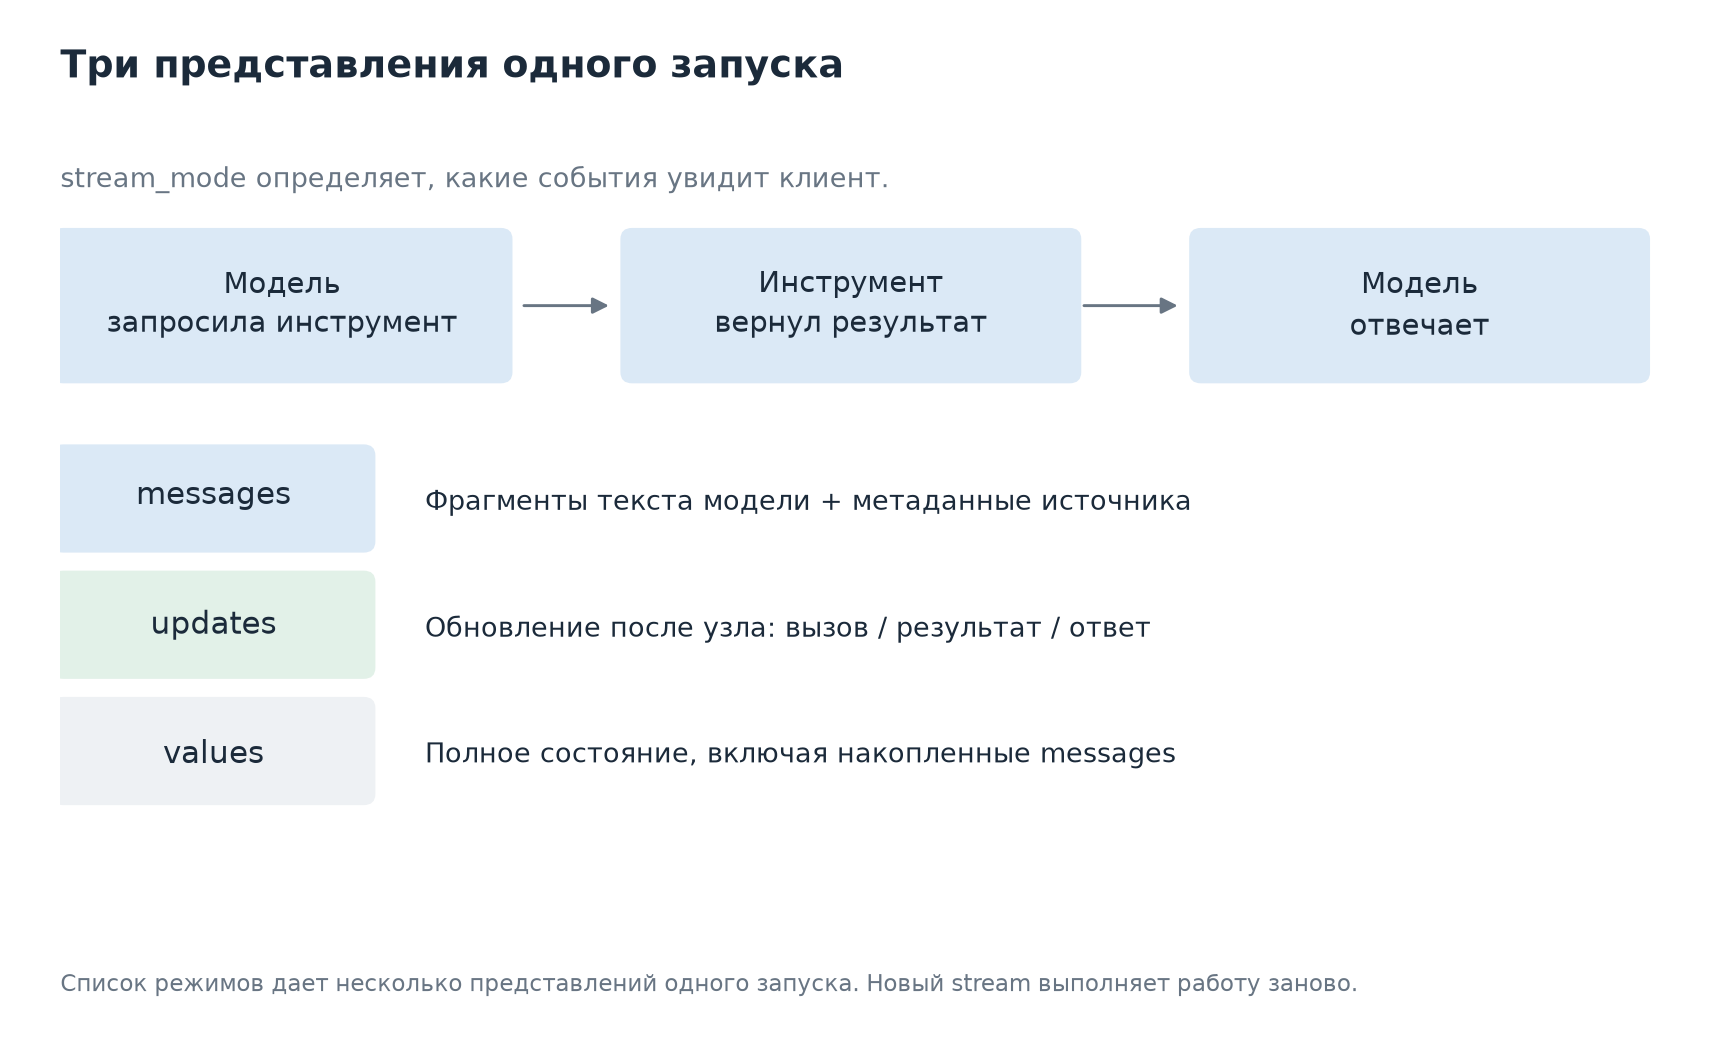


In [ ]:
# Настроить chat_model: выбрать модель, адрес провайдера и ключ из окружения.

import os  # читать настройки провайдера из переменных окружения

from dotenv import load_dotenv  # загрузить настройки из файла .env
from langchain.chat_models import init_chat_model  # создать модель с адаптером выбранного провайдера

load_dotenv()  # загрузить .env в переменные окружения


def chat_model(size: str = "cheap", **kwargs):  # выбрать модель и передать дополнительные настройки запроса
    """A model object for the configured provider. A dozen lines, copy them once."""
    name = os.environ[f"MODEL_{size.upper()}"]  # cheap выбирает MODEL_CHEAP, strong выбирает MODEL_STRONG
    secret = os.environ["LLM_API_KEY"]  # взять ключ из окружения, не записывая его в ноутбук
    if os.getenv("LLM_REASONING_EFFORT"):  # необязательная настройка рассуждений модели
        kwargs.setdefault("reasoning_effort", os.environ["LLM_REASONING_EFFORT"])  # применить настройку, если вызывающий код не задал свою
    kwargs.setdefault("timeout", 120)  # ограничить время одной попытки запроса
    kwargs.setdefault("max_tokens", 8192)  # ограничить размер ответа модели
    if os.getenv("LLM_PROVIDER", "openai_compat") == "google_genai":  # выбрать собственный адаптер Gemini
        return init_chat_model(f"google_genai:{name}", api_key=secret, **kwargs)  # вернуть модель для Gemini
    return init_chat_model(  # для совместимого API передать также адрес сервера
        f"openai:{name}", api_key=secret, base_url=os.environ["LLM_BASE_URL"], **kwargs  # имя, ключ, адрес провайдера и настройки запроса
    )


model = chat_model()  # этим объектом будут пользоваться все примеры занятия
print("Model:", os.environ["MODEL_CHEAP"])  # показать выбранную модель без вывода ключа


## Что именно будет делать агент

`lookup_contact` находит адрес по роли: например, `dean` означает декана. Это чтение данных, поэтому подтверждение здесь не требуется.
`send_email` принимает адрес `to` и текст `body`, затем добавляет их в `OUTBOX`.
В настоящем приложении на месте `OUTBOX.append(...)` был бы вызов почтового сервиса. В уроке письма никуда не уходят.

Декоратор `@tool` сообщает модели, как называется функция, для чего она нужна и какие аргументы принимает.
Строки в тройных кавычках описывают инструменты для модели. Комментарии после `#` помогают читать код человеку.
Первый прямой вызов `lookup_contact.invoke(...)` проверяет только инструмент; агент еще не запущен.

Для формы в конце понадобится `ipywidgets` — пакет уже добавлен в окружение курса.
В репозитории курса обновите окружение командой `uv sync --project materials`.
В отдельном окружении Jupyter выполните `%pip install "ipywidgets>=8.1,<9"`, затем перезапустите ядро и снова выполните ноутбук.


In [ ]:
# Подготовить адресную книгу и локальную имитацию отправки.

from langchain_core.tools import tool  # превратить Python-функцию в доступный модели инструмент

CONTACTS = {"dean": "dean@university.example", "lab manager": "lab-manager@university.example"}  # учебная адресная книга: роль → адрес
OUTBOX = []  # новые записи появляются только при выполнении send_email


@tool  # схема аргументов и описание функции станут доступны модели
def lookup_contact(name: str) -> str:  # на входе роль человека, на выходе адрес или просьба уточнить
    """Look up an email address by role: dean or lab manager."""
    return CONTACTS.get(name.strip().lower(), "Unknown contact. Ask the user to clarify.")  # убрать пробелы, привести роль к нижнему регистру, найти адрес


@tool  # схема аргументов и описание функции станут доступны модели
def send_email(to: str, body: str) -> str:  # этот инструмент меняет данные, поэтому его будем подтверждать
    """Send an email to an address obtained from lookup_contact."""
    OUTBOX.append({"to": to, "body": body})  # только список Python, без SMTP и HTTP
    return f"Sent to {to}."  # вернуть модели результат выполнения инструмента


print("Contact:", lookup_contact.invoke({"name": "dean"}))  # вызвать инструмент напрямую и проверить адресную книгу
print("Outbox:", OUTBOX)  # проверить, что до запуска агента список отправок пуст


## Подключаем подтверждение к готовому агенту

В следующей ячейке `make_agent` свяжет модель, инструменты, middleware и SQLite.
`interrupt_on` задает правила: поиск проходит сразу, отправка останавливается до решения человека.
**Названия решений определены библиотекой.** `allowed_decisions` выбирает, какие из них разрешить для этого инструмента.

В проверенном окружении LangChain 1.3.14 доступны `approve`, `edit`, `reject` и `respond`.
Для письма выбраны первые три. `respond` позволяет человеку самому вернуть результат вместо выполнения инструмента, например ответить на `ask_user`.
Произвольное слово вроде `confirm` не станет новым типом решения; кнопка с такой надписью должна передать библиотеке `approve`.

`new_config` создает новый `thread_id` — идентификатор разговора. При продолжении паузы нужен прежний `config`, иначе агент не найдет ее.


In [ ]:
# Подключить подтверждение отправки и сохранять состояние в SQLite.

import sqlite3  # открыть локальную базу для сохранения состояния
from pathlib import Path  # получить полный путь к файлу базы
from uuid import uuid4  # создавать отдельный идентификатор для каждого учебного разговора
from langchain.agents import create_agent  # собрать знакомый цикл модели и инструментов
from langchain.agents.middleware import HumanInTheLoopMiddleware  # останавливать выбранные инструменты до выполнения
from langgraph.checkpoint.sqlite import SqliteSaver  # сохранять историю и ожидающее решение в SQLite
from langgraph.types import Command  # передавать решение в уже приостановленный запуск

# постоянный файл нужен, чтобы пауза пережила пересоздание соединения
DB_PATH = Path(os.getenv("HITL_DB_PATH", "hitl-demo.db")).resolve()  # один и тот же файл понадобится при восстановлении паузы
conn = sqlite3.connect(DB_PATH, check_same_thread=False)  # разрешить использование соединения рабочими потоками LangGraph
checkpointer = SqliteSaver(conn)  # дать агенту способ сохранять и читать состояние разговора
# Инструкции модели: найти адрес, запросить отправку, учесть решение человека.
SYSTEM = """You are an email assistant. Use lookup_contact to find requested addresses.
When asked to send, look up the address and then call send_email once.
The application handles approval; do not ask for approval in your text.
After a rejected tool call, acknowledge the rejection and stop. Do not retry.
A reviewer may edit the recipient or body; these edits are intentional.
After a successful send, confirm the actual recipient. Do not offer another send.
Answer other questions briefly.
"""


def make_agent(saver):  # собирать того же агента с переданным чекпоинтером
    return create_agent(  # вернуть готового агента с правилами подтверждения
        model=model, tools=[lookup_contact, send_email], system_prompt=SYSTEM,  # подключить модель, два инструмента и инструкции
        middleware=[HumanInTheLoopMiddleware(interrupt_on={  # указать, перед какими инструментами нужно решение человека
            "lookup_contact": False,  # разрешить поиск адреса без остановки
            "send_email": {"allowed_decisions": ["approve", "edit", "reject"]},  # разрешить три готовых типа решения из библиотеки
        })],
        checkpointer=saver,  # состояние паузы привязано к thread_id
    )


def new_config(label):  # подготовить настройки отдельного учебного разговора
    # новый пример получает отдельный разговор; продолжение использует прежний config
    return {"configurable": {"thread_id": f"{label}-{uuid4().hex}"}, "recursion_limit": 20}  # thread_id связывает запуск с его паузой; лимит ограничивает шаги


agent = make_agent(checkpointer)  # собрать агента, который сохраняет состояние в этой базе
LOOKUP = {"messages": [{"role": "user", "content": "Find the dean's email address. Do not send anything."}]}  # первый запрос: только найти адрес
SEND = {"messages": [{"role": "user", "content": "Tell the dean the quarterly report is ready. Send a short email."}]}  # второй запрос: подготовить отправку письма
print("Protected tool: send_email | decisions: approve, edit, reject")  # напомнить, какой инструмент остановится перед выполнением
print("Checkpoint file:", DB_PATH.name)  # показать имя файла с сохраненными разговорами


## Смотрим, что хранится в разговоре

Теперь попросим только адрес. `values` покажет, как к вопросу добавляются запрос инструмента, результат поиска и ответ модели.
`human`, `ai`, `tool` в выводе — типы сообщений, а не список выполненных функций.


In [ ]:
# Посмотреть, как растет состояние при поиске адреса.

for state in agent.stream(LOOKUP, config=new_config("values"), stream_mode="values"):  # запустить поиск и получать полное состояние после шагов
    print([message.type for message in state["messages"]])  # типы всех накопленных сообщений
assert OUTBOX == []  # убедиться, что поиск адреса не отправлял писем


## Как узнать, что поиск уже закончился

Для статуса «Адрес найден» нужно дождаться результата `lookup_contact`.
Запись в `tool_calls` означает только намерение модели вызвать инструмент. До выполнения дело еще может не дойти: например, вмешается middleware.

В событии `updates` ключ — имя узла, а значение — изменения, которые он внес в состояние.
Цикл ниже берет из изменения новые сообщения и печатает их тип и содержимое.
`AIMessage` с вызовом показывает запрос, а `ToolMessage` содержит результат инструмента либо сообщение middleware об отказе.
Некоторые узлы меняют другие поля или ничего не добавляют: `(delta or {}).get("messages", [])` позволяет пропустить их без ошибки.

Ожидаемый ход этого примера: запрос поиска → найденный адрес → ответ модели. Список `OUTBOX` должен остаться пустым.


In [ ]:
# Печатать запросы инструментов и их результаты по мере выполнения.

for update in agent.stream(LOOKUP, config=new_config("updates"), stream_mode="updates"):  # запустить отдельный поиск и получать изменения состояния
    for node, delta in update.items():  # взять имя завершенного узла и внесенное им изменение
        for message in (delta or {}).get("messages", []):  # взять новые сообщения; некоторые узлы их не добавляют
            calls = getattr(message, "tool_calls", [])  # запрос модели еще не означает выполнение
            print(node, "|", message.type, "|", calls or message.content)  # показать источник, тип сообщения и вызов либо ответ
assert OUTBOX == []  # убедиться, что поиск адреса не отправлял писем


## Как показывать ответ по мере появления

Теперь нужен другой эффект: пользователь видит начало ответа, пока модель еще генерирует продолжение.
Режим `messages` передает пары: фрагмент сообщения и сведения об источнике. В цикле это `chunk` и `metadata`.
Проверка `AIMessageChunk` оставляет фрагменты модели, а `chunk.text` — их текстовую часть.

`end=""` не вставляет перенос после каждого кусочка. `flush=True` просит сразу показать текст, не задерживая его в буфере вывода.
В форме вместо `print` будем дописывать этот текст в поле ответа.
Один фрагмент может содержать несколько токенов; это зависит от провайдера.
Стриминг помогает раньше увидеть начало ответа, но сам по себе не делает весь запрос быстрее.


In [ ]:
# Вывести текст модели по мере поступления фрагментов.

from langchain_core.messages import AIMessageChunk  # распознавать фрагменты ответа модели среди событий

for chunk, metadata in agent.stream(LOOKUP, config=new_config("messages"), stream_mode="messages"):  # получать фрагмент и сведения о его источнике
    if isinstance(chunk, AIMessageChunk) and chunk.text:  # показывать только непустой текст модели
        print(chunk.text, end="", flush=True)  # flush не дает консоли копить вывод
print()  # перевести строку после потока фрагментов
assert OUTBOX == []  # убедиться, что поиск адреса не отправлял писем


## Соединяем текст, статусы и подтверждение

`watch_run` — небольшая функция для наблюдения за одним запуском в консоли.
На вход она получает `value`: первоначальный запрос либо `Command` с решением человека, и `config` нужного разговора.
Один `stream` с двумя режимами возвращает пары `(mode, event)`. По `mode` выбираем, как прочитать `event`.

- `messages`: дописываем фрагмент ответа модели.
- `updates` с `__interrupt__`: показываем запрос подтверждения и сохраняем его в `pauses`.
- остальные `updates`: печатаем запросы инструментов (`REQUEST`) и полученные результаты (`RESULT`).

В `REVIEW` будут `action_requests` с именами и аргументами действий, а также правила выбора решения.
Когда агент остановился, цикл заканчивается и функция возвращает список пауз. Она не ждет нажатия кнопки внутри `stream`.
Ниже отправим решение отдельным вызовом, с тем же `config`. В конце ноутбука этот второй вызов сделает обработчик кнопки.

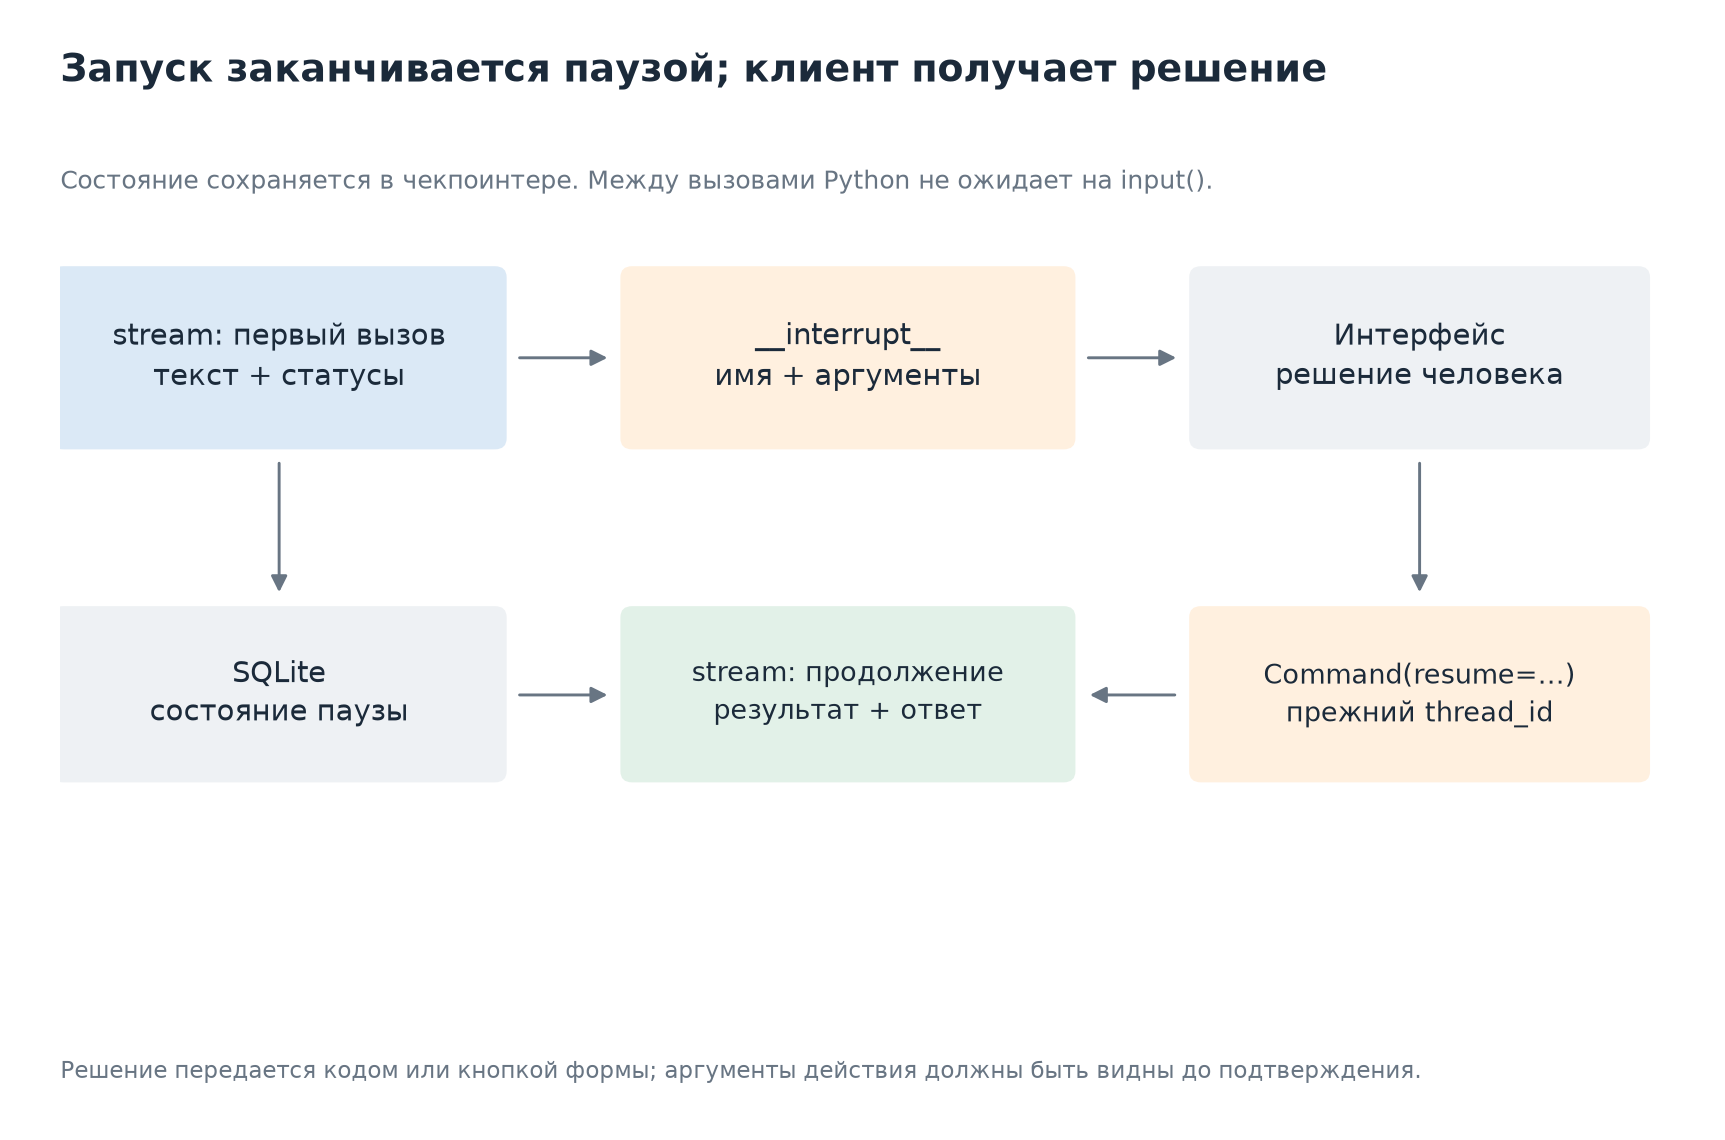


In [ ]:
# Обработать два режима в одном потоке и вернуть найденные паузы.

import json  # удобно печатать вложенные аргументы запроса подтверждения


def watch_run(value, config):  # показать один запуск; value содержит запрос или решение
    pauses = []  # собрать запросы, для которых еще требуется решение человека
    for mode, event in agent.stream(value, config=config, stream_mode=["messages", "updates"]):  # читать текст и изменения состояния одного запуска
        if mode == "messages":  # разобрать событие с фрагментом ответа модели
            chunk, metadata = event  # отделить фрагмент от сведений об источнике
            if isinstance(chunk, AIMessageChunk) and chunk.text:  # показывать только непустой текст модели
                print(chunk.text, end="", flush=True)  # сразу дописать фрагмент к уже показанному ответу
        elif "__interrupt__" in event:  # получить запрос подтверждения, созданный middleware
            # сохранить весь запрос подтверждения для последующего решения
            pauses.extend(event["__interrupt__"])  # сохранить объекты пауз, чтобы вернуть их вызывающему коду
            for pause in event["__interrupt__"]:  # показать каждую найденную паузу
                print("\nREVIEW:", json.dumps(pause.value, ensure_ascii=False, indent=2))  # напечатать инструмент, аргументы и разрешенные решения
        else:  # оставшееся событие содержит обновления завершенных узлов
            for node, delta in event.items():  # взять имя узла и добавленные им данные
                for message in (delta or {}).get("messages", []):  # взять новые сообщения; некоторые узлы их не добавляют
                    for call in getattr(message, "tool_calls", []):  # найти вызовы, которые запросила модель
                        print("\nREQUEST:", call["name"], call["args"])  # показать намерение вызвать инструмент; он еще мог не выполниться
                    if message.type == "tool":  # результат инструмента приходит отдельным сообщением
                        print("\nRESULT:", message.name, message.content)  # показать фактический результат инструмента либо отказ middleware
    print()  # перевести строку после потока фрагментов
    return pauses  # вернуть ожидающие решения; пустой список означает отсутствие пауз


print("Client handler ready.")  # функция определена; сам агент пока не запускался


In [ ]:
# Дойти до запроса подтверждения и проверить, что отправка еще не выполнена.

approve_cfg = new_config("approve")  # запомнить разговор, который позже нужно будет продолжить
pending = watch_run(SEND, approve_cfg)  # попросить отправку; middleware должен остановить инструмент
assert len(pending) == 1  # проверить, что агент запросил ровно одно подтверждение
actions = pending[0].value["action_requests"]  # достать действия, предложенные человеку на рассмотрение
assert len(actions) == 1 and actions[0]["name"] == "send_email"  # убедиться, что подтверждается именно одна отправка
assert OUTBOX == []  # middleware остановил вызов до входа в send_email
print("Pending action:", actions[0]["name"])  # назвать ожидающий решения инструмент
print("Outbox before approval:", OUTBOX)  # показать, что письма еще нет в списке отправок


## Проверяем каждое решение отдельно

До этого места агент только подготовил вызов `send_email`. Пустой `OUTBOX` подтверждает, что инструмент еще не отправлял письмо.
`actions[0]["args"]` — тот адрес и текст, которые нужно показать человеку перед решением.

- `approve`: выполнить исходный вызов; изменения в полях интерфейса сами по себе его не исправляют.
- `reject`: пропустить вызов и сообщить модели причину отказа; новая запись в `OUTBOX` появиться не должна.
- `edit`: сразу выполнить вызов с `edited_action`; второго подтверждения после этого решения нет.

Следующие три ячейки проверяют эти варианты по очереди. Одобрение продолжает уже открытый разговор `approve_cfg`.
Отказ и исправление начинаются с отдельных новых разговоров, чтобы результаты не зависели друг от друга.
Решения пока записаны прямо в коде; в форме в конце их будет выбирать человек.
Финальную реплику модели оценивайте отдельно: она может предложить еще одно действие, даже если текущая отправка уже завершена.
Проверки ниже устанавливают, какой инструмент действительно выполнился и с какими аргументами.
Если в одном запросе несколько `action_requests`, нужен список решений в том же порядке. Здесь проверяем одно письмо за раз.

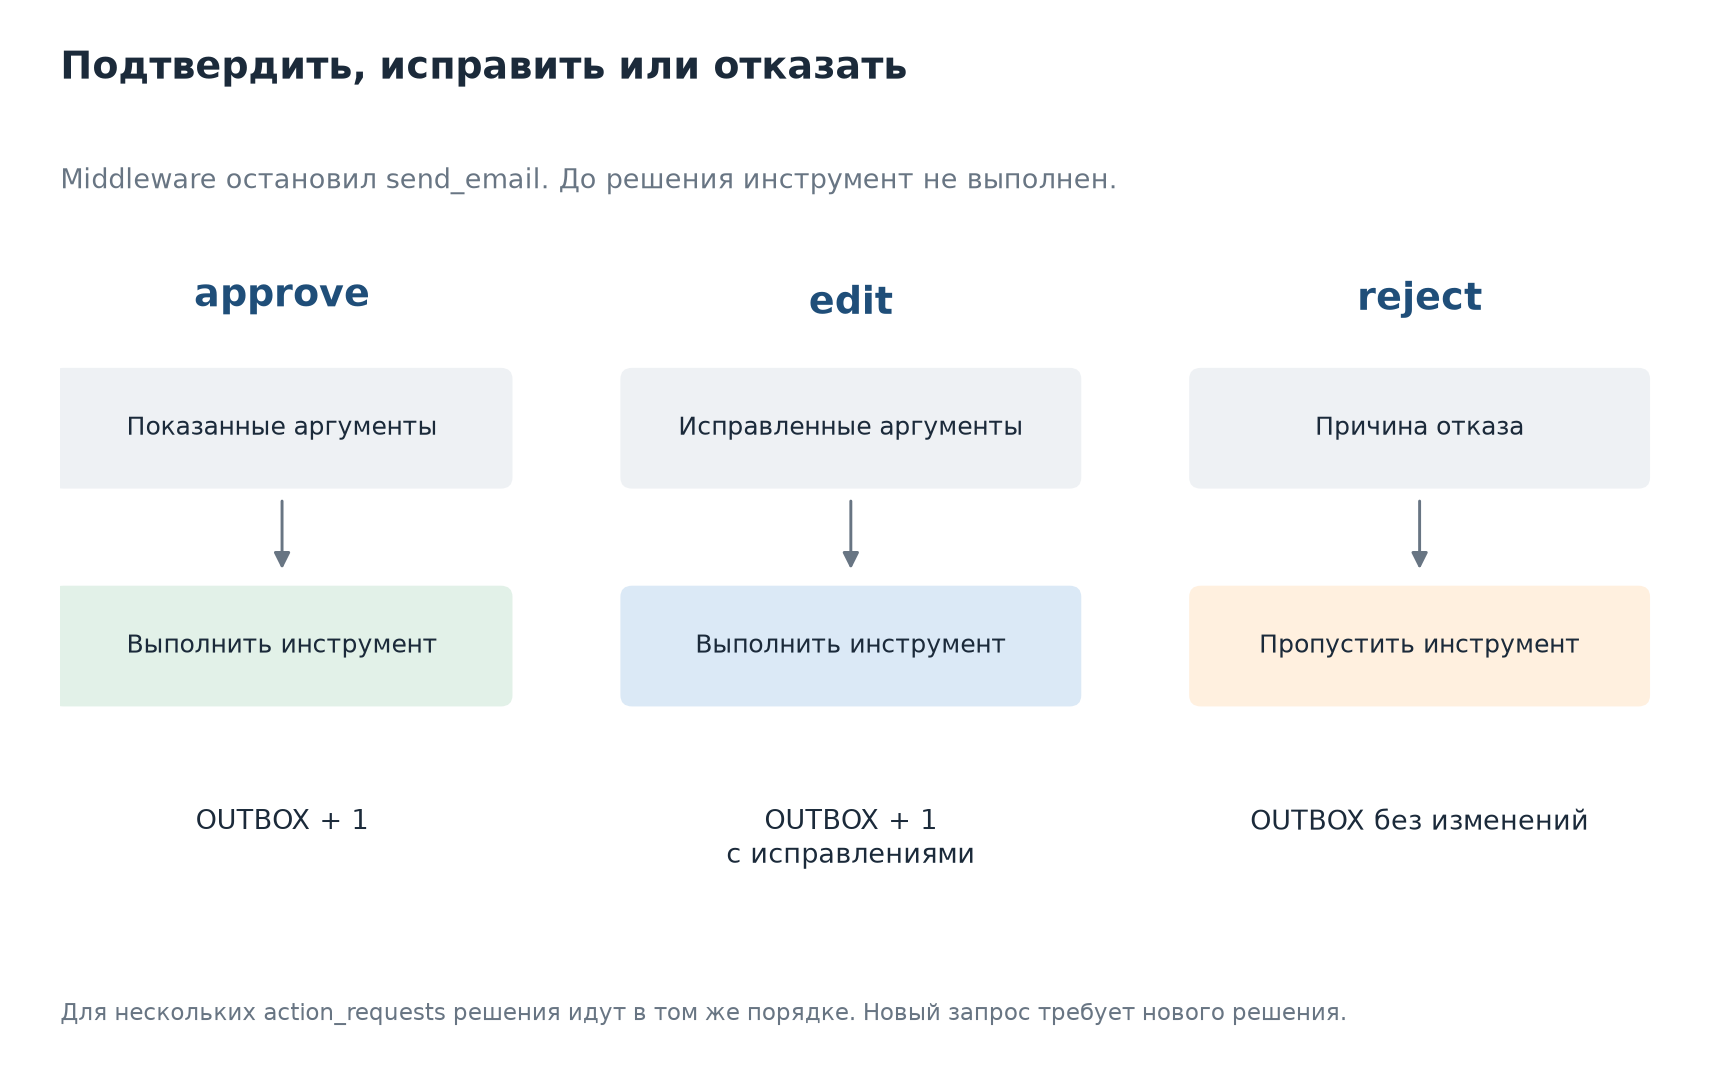


In [ ]:
# Продолжить тот же разговор с решением approve и сравнить запись с показанными аргументами.

remaining = watch_run(Command(resume={"decisions": [{"type": "approve"}]}), approve_cfg)  # передать согласие в прежний разговор, не повторяя SEND
assert not remaining  # убедиться, что агент завершился без нового запроса подтверждения
assert OUTBOX == [actions[0]["args"]]  # выполнено именно показанное человеку действие
print("Outbox after approval:", OUTBOX)  # показать запись, появившуюся после одобрения


In [ ]:
# Отказать в отправке и проверить, что число писем не изменилось.

reject_cfg = new_config("reject")  # создать отдельный разговор для примера отказа
before = len(OUTBOX)  # запомнить число отправок перед проверяемым действием
waiting = watch_run(SEND, reject_cfg)  # снова подготовить письмо, но остановиться до отправки
assert len(waiting) == 1  # проверить, что ожидается одно решение человека
remaining = watch_run(Command(resume={"decisions": [  # передать список решений в приостановленный запуск
    {"type": "reject", "message": "Do not send this email. Stop this request."}  # запретить отправку и объяснить модели причину
]}), reject_cfg)  # продолжить именно разговор из примера отказа
assert not remaining  # повторный запрос отправки потребовал бы нового решения
assert len(OUTBOX) == before  # проверить отсутствие новой записи после отказа
print("Rejected: no new outbox entry.")  # вывести результат проверки


In [ ]:
# Исправить адрес и текст перед выполнением инструмента.

edit_cfg = new_config("edit")  # создать отдельный разговор для редактирования
before = len(OUTBOX)  # запомнить число отправок перед проверяемым действием
waiting = watch_run(SEND, edit_cfg)  # получить новый черновик, ожидающий решения
assert len(waiting) == 1  # проверить, что ожидается одно решение человека
edited = {"name": "send_email", "args": {  # собрать окончательные аргументы выбранного инструмента
    "to": CONTACTS["lab manager"], "body": "The quarterly report is ready for internal review."  # заменить адресата и текст письма
}}
remaining = watch_run(Command(resume={"decisions": [  # передать список решений в приостановленный запуск
    {"type": "edit", "edited_action": edited}  # edit сразу разрешает выполнение с исправлениями
]}), edit_cfg)  # использовать разговор, в котором был показан этот черновик
assert not remaining and len(OUTBOX) == before + 1  # проверить завершение и ровно одну новую отправку
assert OUTBOX[-1] == edited["args"]  # сохранить только окончательно одобренные аргументы
print("Edited send:", OUTBOX[-1])  # показать фактически использованные адрес и текст


## Пользователь вернулся позже: как показать ему тот же черновик

Представьте: черновик готов, но пользователь пока не решил, отправлять ли его. Python-вызов уже закончился.
Пауза и аргументы инструмента сохранены в SQLite вместе с состоянием разговора.
Чтобы прочитать их позже, нужны тот же файл базы, тот же агент и прежний `thread_id`.

Ниже закроем соединение с базой, откроем его заново и пересоздадим агента. Ядро Jupyter при этом продолжит работать.
`get_state(restore_cfg)` прочитает сохраненное состояние. В `snapshot.tasks` находятся **служебные записи выполнения узлов LangGraph**.
Это не поручения пользователя и не задания студентов. В поле `.interrupts` каждой записи лежат запросы, на которых выполнение остановилось.
Два коротких цикла соберут эти запросы в `restored`, чтобы проверить: из базы прочитано именно прежнее письмо.

Для продолжения передаем решение через `Command(resume=...)`. Повторять исходный запрос `SEND` не нужно.
`OUTBOX` остается списком текущего Python: этот пример проверяет сохранение паузы, а не сохранение отправленных писем после перезапуска ядра.

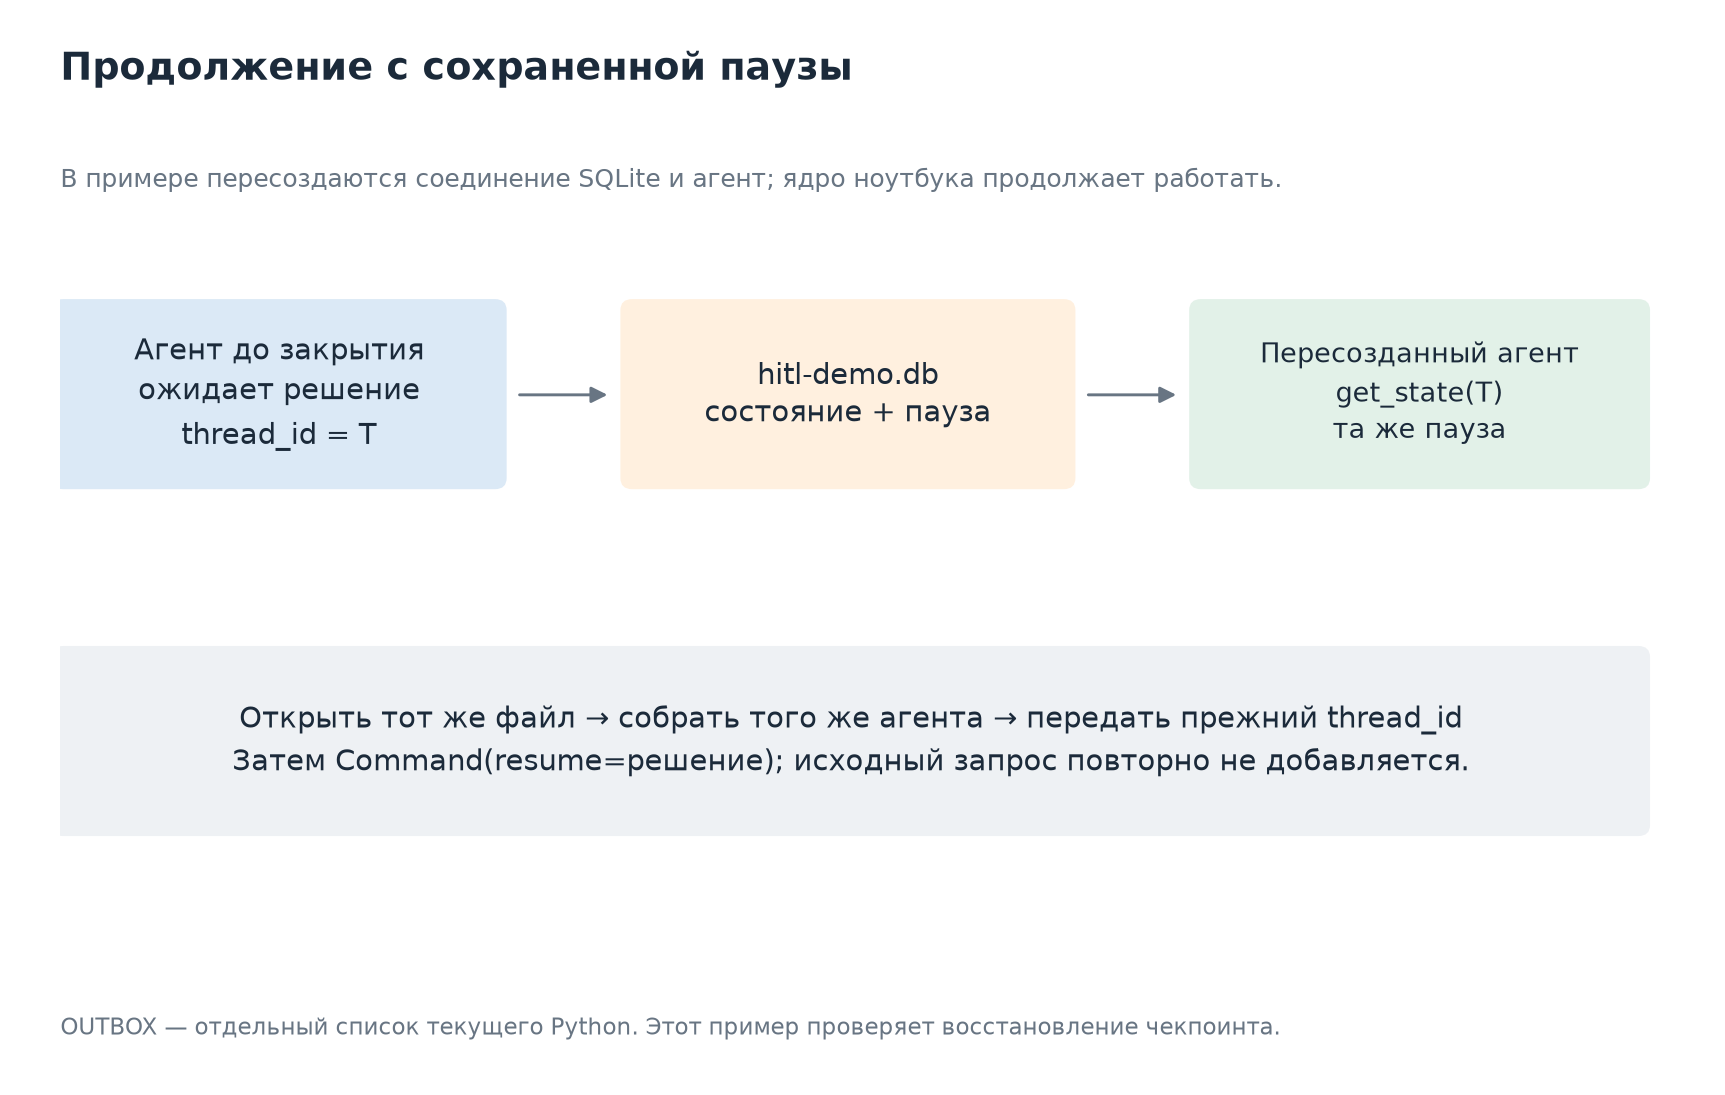


In [ ]:
# Пересоздать соединение и агента, затем прочитать сохраненную паузу.

restore_cfg = new_config("restore")  # запомнить идентификатор разговора для восстановления
waiting = watch_run(SEND, restore_cfg)  # создать ожидающее подтверждения письмо
assert len(waiting) == 1  # проверить, что ожидается одно решение человека
saved_payload = waiting[0].value  # запомнить запрос только для последующего сравнения
conn.close()  # закрыть прежнее соединение; данные уже сохранены в файле
conn = sqlite3.connect(DB_PATH, check_same_thread=False)  # открыть тот же файл заново
checkpointer = SqliteSaver(conn)  # дать агенту способ сохранять и читать состояние разговора
agent = make_agent(checkpointer)  # собрать агента, который сохраняет состояние в этой базе
# состояние читается из SQLite, а не из прежнего объекта агента
snapshot = agent.get_state(restore_cfg)  # прочитать состояние этого разговора из чекпоинтера
restored = []  # сюда попадут сохраненные запросы подтверждения
for execution in snapshot.tasks:  # служебные записи выполнения узлов, не задачи пользователя
    for pause in execution.interrupts:  # паузы, на которых остановилось это выполнение
        restored.append(pause)  # сохранить запрос, который нужно снова показать человеку
assert len(restored) == 1 and restored[0].value == saved_payload  # сравнить прочитанное из базы подтверждение с исходным
print("Restored action:", restored[0].value["action_requests"][0]["name"])  # показать инструмент, который по-прежнему ждет решения
print("Still pending:", bool(snapshot.next))  # True означает, что остались невыполненные шаги


In [ ]:
# Завершить восстановленный запуск, сохранив прежний thread_id.

before = len(OUTBOX)  # запомнить число отправок перед проверяемым действием
remaining = watch_run(Command(resume={"decisions": [{"type": "approve"}]}), restore_cfg)  # продолжить восстановленный разговор с решением approve
assert not remaining and len(OUTBOX) == before + 1  # проверить завершение и ровно одну новую отправку
print("Restored run completed; new outbox entries:", len(OUTBOX) - before)  # показать число отправок именно этого продолжения


## Две оговорки для своего приложения

**Если пишете собственный `interrupt()`:** после продолжения узел выполняется с начала; код до остановки может выполниться повторно.
Поэтому отправку, запись или удаление размещают после получения и проверки согласия. В показанном агенте это уже обеспечивает middleware.
Для защиты от повторной отправки при сбое внешний сервис дополнительно должен распознавать повтор операции по ее идентификатору.

**Чекпоинт не отменяет сделанное снаружи:** возвращение к старому состоянию агента не удалит уже отправленное письмо или созданную задачу.
Если сервис поддерживает отмену, это отдельное действие приложения. Для подключения подтверждений отдельный эксперимент с откатом не требуется.


## Где проверить цепочку действий в Langfuse

`OUTBOX` отвечает на вопрос «Что было отправлено?». Трейс помогает выяснить, какие вызовы к этому привели и где возникла ошибка.
Например, если появилась лишняя запись, по трейсу можно проверить, не вызвал ли агент инструмент повторно.

В следующей ячейке четыре этапа: подключить запись событий, дойти до паузы, одобрить отправку, отправить накопленные события в Langfuse.
`CallbackHandler` собирает события. Один `langfuse_session_id` связывает обращение до паузы и обращение с решением в общую сессию.
`flush()` дожидается отправки событий, чтобы их можно было сразу открыть в интерфейсе.

Найдите сессию по напечатанному идентификатору. До решения должен быть поиск контакта и остановка middleware, но не выполненный `send_email`.
В продолжении должен появиться вызов инструмента `send_email` и его результат. Текст модели «отправлено» сам по себе этого не доказывает.
Следующее занятие подробно посвящено Langfuse; здесь достаточно увидеть границу между предложенным и выполненным действием.


In [ ]:
# Записать в Langfuse запуск до паузы и одобренное продолжение.

from langfuse import get_client  # получить клиент отправки событий в Langfuse
from langfuse.langchain import CallbackHandler  # записывать вызовы модели и инструментов

# 1. Подключить запись событий и связать оба обращения одним идентификатором.
trace_cfg = new_config("traced")  # создать отдельный разговор для проверки трейса
trace_cfg["callbacks"] = [CallbackHandler()]  # записывать события вызовов с этим config
trace_cfg["metadata"] = {"langfuse_session_id": trace_cfg["configurable"]["thread_id"]}  # объединить трейсы разговора

# 2. Подготовить письмо и остановиться перед отправкой.
before = len(OUTBOX)  # запомнить число отправок перед запуском
waiting = watch_run(SEND, trace_cfg)  # получить черновик и запрос подтверждения
assert len(waiting) == 1  # убедиться, что инструмент ждет решения

# 3. Одобрить отправку и проверить результат.
remaining = watch_run(Command(resume={"decisions": [{"type": "approve"}]}), trace_cfg)  # продолжить тот же разговор
assert not remaining and len(OUTBOX) == before + 1  # новая запись одна, ожидающих решений нет

# 4. Дождаться отправки событий, затем найти сессию в интерфейсе Langfuse.
get_client().flush()  # отправить события сейчас, а не ждать фонового накопления
print("Trace session:", trace_cfg["metadata"]["langfuse_session_id"])  # значение для поиска сессии


## Теперь тот же сценарий с кнопками

Вместо ручной записи `Command(...)` соберем маленький рабочий интерфейс прямо в Jupyter.
Пользователь нажимает `Prepare draft`, видит ход работы, адрес и текст. До выбора решения письмо остается неотправленным.
`Approve original` отправляет исходный черновик; `Send edited` отправляет содержимое полей; `Reject` отменяет отправку.

Здесь нужны два направления обмена:
1. **Агент → интерфейс.** Цикл читает `agent.stream(...)`: фрагменты дописываются в поле ответа, а `__interrupt__` заполняет поля черновика.
2. **Человек → агент.** Обработчик кнопки собирает решение и передает `Command(resume=...)` с сохраненным `thread_id`.

События агента приходят из LangGraph. Нажатия кнопок приходят из Jupyter через `ipywidgets`. Связь между ними ниже написана явно.
Модель, инструменты, middleware и SQLite остаются теми же. Каждое обращение формы открывает свое соединение с базой и закрывает его после работы.
Поэтому форма продолжит работать даже после последней ячейки, закрывающей основное соединение примеров.

Сначала создадим элементы экрана. Код пока не вызывает модель: запуск начнется только по кнопке.


In [ ]:
# Создать поля и кнопки формы; агент пока не запускается.

import ipywidgets as widgets  # кнопки и поля, связанные с Python-ядром Jupyter
from IPython.display import display  # показать собранную форму под ячейкой
from contextlib import closing  # закрывать соединение формы после каждого обращения

ui_state = {"config": None, "pending": None, "busy": False}  # разговор, пауза и защита от одновременного запуска
ui_start = widgets.Button(description="Prepare draft")  # начать новый запрос на подготовку письма
ui_status = widgets.Label(value="Click Prepare draft to start.")  # показывать текущий этап работы
ui_answer = widgets.Textarea(  # поле с постепенно появляющимся ответом
    description="Agent:", disabled=True,  # ответ модели нельзя править вручную
    layout=widgets.Layout(width="100%", height="100px"),  # задать ширину и высоту поля
)
ui_to = widgets.Text(  # адрес получателя появится после подготовки черновика
    description="To:", disabled=True,  # до паузы поле заблокировано
    layout=widgets.Layout(width="100%"),  # использовать ширину области вывода
)
ui_body = widgets.Textarea(  # показать весь текст письма для проверки
    description="Body:", disabled=True,  # разрешить правку только при ожидающем решении
    layout=widgets.Layout(width="100%", height="130px"),  # оставить место для нескольких строк
)
ui_approve = widgets.Button(description="Approve original", disabled=True)  # отправить исходные аргументы
ui_edit = widgets.Button(description="Send edited", disabled=True)  # отправить значения полей To и Body
ui_reject = widgets.Button(description="Reject", disabled=True)  # отказаться от отправки
ui_decisions = [ui_approve, ui_edit, ui_reject]  # менять доступность трех кнопок вместе


### Что происходит после Prepare draft

Следующая функция запускает агента и переносит события в интерфейс.
Ветка `messages` дописывает ответ в `ui_answer`; ветка `__interrupt__` заполняет `ui_to` и `ui_body`.
После остановки кнопки решений становятся доступны. Пока агент работает, они отключены.

Каждый вызов открывает тот же файл SQLite и использует `ui_state["config"]`.
Новый объект агента поэтому продолжает сохраненный разговор. Открытое соединение между нажатиями не требуется.
Это та же логика, которую затем можно разместить в обработчике запроса на сервере.


In [ ]:
# Связать события настоящего агента с полями формы.

def run_in_form(value):  # принять первоначальный запрос либо решение человека
    ui_state["busy"] = True  # не принимать новый запуск, пока обрабатывается этот
    ui_state["pending"] = None  # старое решение уже передается агенту
    for control in [ui_start, ui_to, ui_body, *ui_decisions]:  # на время запроса заморозить форму
        control.disabled = True  # исключить изменения полей во время выполнения
    ui_status.value = "Working..."  # показать, что обращение началось
    before = len(OUTBOX)  # по реальным записям проверять результат отправки

    try:  # при ошибке показать ее в форме и оставить Python-исключение
        with closing(sqlite3.connect(DB_PATH, check_same_thread=False)) as ui_conn:  # открыть тот же файл состояния
            ui_agent = make_agent(SqliteSaver(ui_conn))  # использовать прежние инструменты и middleware
            for mode, event in ui_agent.stream(  # читать текст и статусы одного запуска
                value,  # первоначальный запрос либо Command с решением
                config=ui_state["config"],  # тот же разговор до и после решения
                stream_mode=["messages", "updates"],  # получать фрагменты и завершенные шаги
            ):
                if mode == "messages":  # пришел фрагмент ответа модели
                    chunk, metadata = event  # отделить фрагмент от его метаданных
                    if isinstance(chunk, AIMessageChunk) and chunk.text:  # пропустить события без текста модели
                        ui_answer.value += chunk.text  # дописать фрагмент в видимое поле
                elif "__interrupt__" in event:  # агент остановился перед инструментом
                    pauses = event["__interrupt__"]  # взять запросы подтверждения этого события
                    assert len(pauses) == 1  # учебная форма обслуживает одну паузу за раз
                    actions = pauses[0].value["action_requests"]  # достать предложенные действия
                    assert len(actions) == 1 and actions[0]["name"] == "send_email"  # форма рассчитана на одно письмо
                    ui_state["pending"] = actions[0]  # запомнить исходный черновик, ожидающий решения
                    ui_to.value = actions[0]["args"]["to"]  # показать адрес, предложенный агентом
                    ui_body.value = actions[0]["args"]["body"]  # показать весь предложенный текст
                else:  # обработать завершенные шаги для статуса поиска
                    for delta in event.values():  # взять изменение состояния каждого завершенного узла
                        for message in (delta or {}).get("messages", []):  # просмотреть новые сообщения
                            if message.type == "tool" and message.name == "lookup_contact":  # поиск вернул результат
                                ui_status.value = f"Address found: {message.content}"  # показать найденный адрес

        if ui_state["pending"] is not None:  # без решения ничего отправлять нельзя
            ui_status.value = "Review the recipient and body, then choose a decision."  # предложить проверить черновик
            for control in [ui_to, ui_body, *ui_decisions]:  # дать доступ к полям и решениям
                control.disabled = False  # пользователь теперь может исправить или подтвердить письмо
        else:  # запуск закончился без нового запроса подтверждения
            added = len(OUTBOX) - before  # посчитать фактические отправки в этом обращении
            ui_status.value = f"Finished. New outbox entries: {added}."  # отказ дает 0, успешная отправка дает 1
            ui_start.disabled = False  # разрешить отдельный новый запрос
    except Exception as error:  # не маскировать сбой под успешную отправку
        ui_status.value = f"Run failed: {type(error).__name__}; inspect the traceback before retrying."  # оставить понятный статус ошибки
        raise  # сохранить исходную ошибку для разбора
    finally:  # снять флаг даже при ошибке
        ui_state["busy"] = False  # текущий Python-вызов уже закончен


### Что происходит после нажатия решения

`on_click` связывает кнопку с Python-функцией. Вызвать ее помогает Jupyter: отдельного веб-сервера для этого примера не нужно.
Функция подготовки создает разговор и передает `SEND`. Функция решения передает `Command(...)`, сохраняя прежний разговор.

После выполнения ячейки нажмите `Prepare draft` и дождитесь черновика.
Сначала попробуйте `Reject`: статус должен показать ноль новых записей. Подготовьте новый черновик и нажмите `Approve original`: должна появиться одна запись.
Для третьего прогона измените адрес или текст и нажмите `Send edited`; проверьте последнюю запись `OUTBOX[-1]`.
`Approve original` игнорирует правки в полях — для их отправки нужна именно `Send edited`.

Это работающий учебный клиент для одного письма. В реальном сервисе проверка доступа и защита от повторных запросов нужны на сервере.
Блокировка кнопок в браузере сама по себе их не заменяет.


In [ ]:
# Превратить нажатия кнопок в запрос или решение для того же разговора.

def prepare_from_button(button):  # Jupyter передает сюда объект нажатой кнопки
    if ui_state["busy"] or ui_state["pending"] is not None:  # не заменять активный запуск или ожидающее решение
        return  # повторное нажатие не создает новую отправку
    ui_state["config"] = new_config("form")  # новый запрос получает отдельный thread_id
    ui_answer.value = ""  # очистить текст предыдущего примера
    ui_to.value, ui_body.value = "", ""  # убрать предыдущий черновик с экрана
    run_in_form(SEND)  # реально вызвать модель и дойти до подтверждения


def decide_from_button(button):  # одна функция обслуживает три кнопки решения
    if ui_state["busy"] or ui_state["pending"] is None:  # принимать решение только для актуального черновика
        return  # повторный клик после завершения не вызывает инструмент
    if button is ui_approve:  # человек согласился с исходным предложением
        decision = {"type": "approve"}  # библиотека возьмет сохраненные исходные аргументы
    elif button is ui_edit:  # человек хочет отправить текущие значения полей
        decision = {  # передать значения, которые человек видит в полях сейчас
            "type": "edit",  # выполнить инструмент с исправленными аргументами
            "edited_action": {  # полный вызов, заменяющий исходное предложение
                "name": "send_email",  # оставить тот же инструмент
                "args": {"to": ui_to.value, "body": ui_body.value},  # взять адрес и текст из формы
            },
        }
    else:  # нажата кнопка отказа
        decision = {"type": "reject", "message": "Do not send this email. Stop this request."}  # запретить отправку
    ui_answer.value += "\n"  # отделить ответ после решения от текста до паузы
    run_in_form(Command(resume={"decisions": [decision]}))  # продолжить прежний thread_id из ui_state


ui_start.on_click(prepare_from_button)  # связать кнопку подготовки с Python-функцией
for button in ui_decisions:  # зарегистрировать общий обработчик трех решений
    button.on_click(decide_from_button)  # нажатие передаст в функцию именно эту кнопку
ui_form = widgets.VBox([  # расположить основные элементы сверху вниз
    ui_start, ui_status, ui_answer, ui_to, ui_body,  # запуск, статус, ответ и черновик
    widgets.HBox(ui_decisions),  # разместить три решения в одну строку
])
display(ui_form)  # показать действующую форму; модель вызывается только по кнопке


## Практика: добавить подтверждение к одному действию своего агента

Выберите инструмент, который что-то меняет: создает задачу, публикует заметку, отправляет уведомление.
Подключите к существующему агенту middleware и постоянный чекпоинтер. До выполнения покажите человеку все значимые аргументы действия.

Проверьте три результата: отказ не меняет данные; одобрение выполняет предложенное действие; исправление выполняет действие с новыми аргументами.
Затем закройте соединение, восстановите паузу и продолжите ее с прежним `thread_id`.
В `runs/session-06.md` коротко запишите, что проверяли и что получилось. Если поведение неожиданное, приложите относящийся к нему трейс.

Обязательного показа успешных выводов напарнику в этом задании нет. Если нужна помощь, полезнее принести конкретный вопрос или воспроизводимую ошибку.
До 3 ноября нужна индивидуальная заявка на проект с выбранным напарником; готовый агент к этому сроку не требуется.
Формальные взаимопроверки проектов остаются на занятиях 10 и 15.


In [ ]:
# Закрыть соединение SQLite после завершения всех примеров.

conn.close()  # файл чекпоинтов остается; для нового запуска пересоздать соединение и агента
print("Checkpoint file preserved:", DB_PATH.name)  # файл и сохраненные паузы остаются на диске


## Что перенести в свой проект

Основной рецепт: `create_agent` + `HumanInTheLoopMiddleware` + постоянный чекпоинтер + решение через `Command(resume=...)`.
Клиент показывает ход работы и черновик, затем отправляет решение в тот же разговор. Сам интерфейс библиотека за приложение не создает.
Для веб-приложения или бота код обращения к агенту переедет на сервер; кнопка будет отправлять ему решение и идентификатор разговора.
Сервер должен проверять доступ к разговору и актуальность паузы, а отправка — быть защищена от повторной обработки одного решения.

- [Подтверждение инструментов](https://docs.langchain.com/oss/python/langchain/human-in-the-loop): настройки и формат решений.
- [Стриминг](https://docs.langchain.com/oss/python/langchain/streaming): режимы событий; здесь используется `stream_mode` из окружения курса.
- [События ipywidgets](https://ipywidgets.readthedocs.io/en/stable/examples/Widget%20Events.html): как связаны нажатие и Python-обработчик.
- [Agent Chat UI](https://github.com/langchain-ai/agent-chat-ui): готовый веб-клиент для совместимого сервера агента; его установка для этой практики не требуется.

Дальше разберем наблюдаемость, стоимость вызовов и поиск проблем по трейсам.
